#Dependencies



In [1]:
!pip install -q paddleocr
!pip install -q paddlepaddle
!pip install -q openai

In [2]:
from IPython.display import display
from datasets import load_dataset

import paddle
from paddleocr import PaddleOCR

import re

from openai import OpenAI
from getpass import getpass


/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


In [ ]:
ds = load_dataset("nikigood/pl-government-docs-mix-ocr-dataset")

In [ ]:
ds.column_names

{'train': ['image']}

In [ ]:
print(ds)

DatasetDict({
    train: Dataset({
        features: ['image'],
        num_rows: 169
    })
})


In [ ]:

print(ds.keys())

train = ds["train"]

print(len(train))

print(train.column_names)

print(train[0])

dict_keys(['train'])
169
['image']
{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=1485x2100 at 0x7BE5883A60D0>}


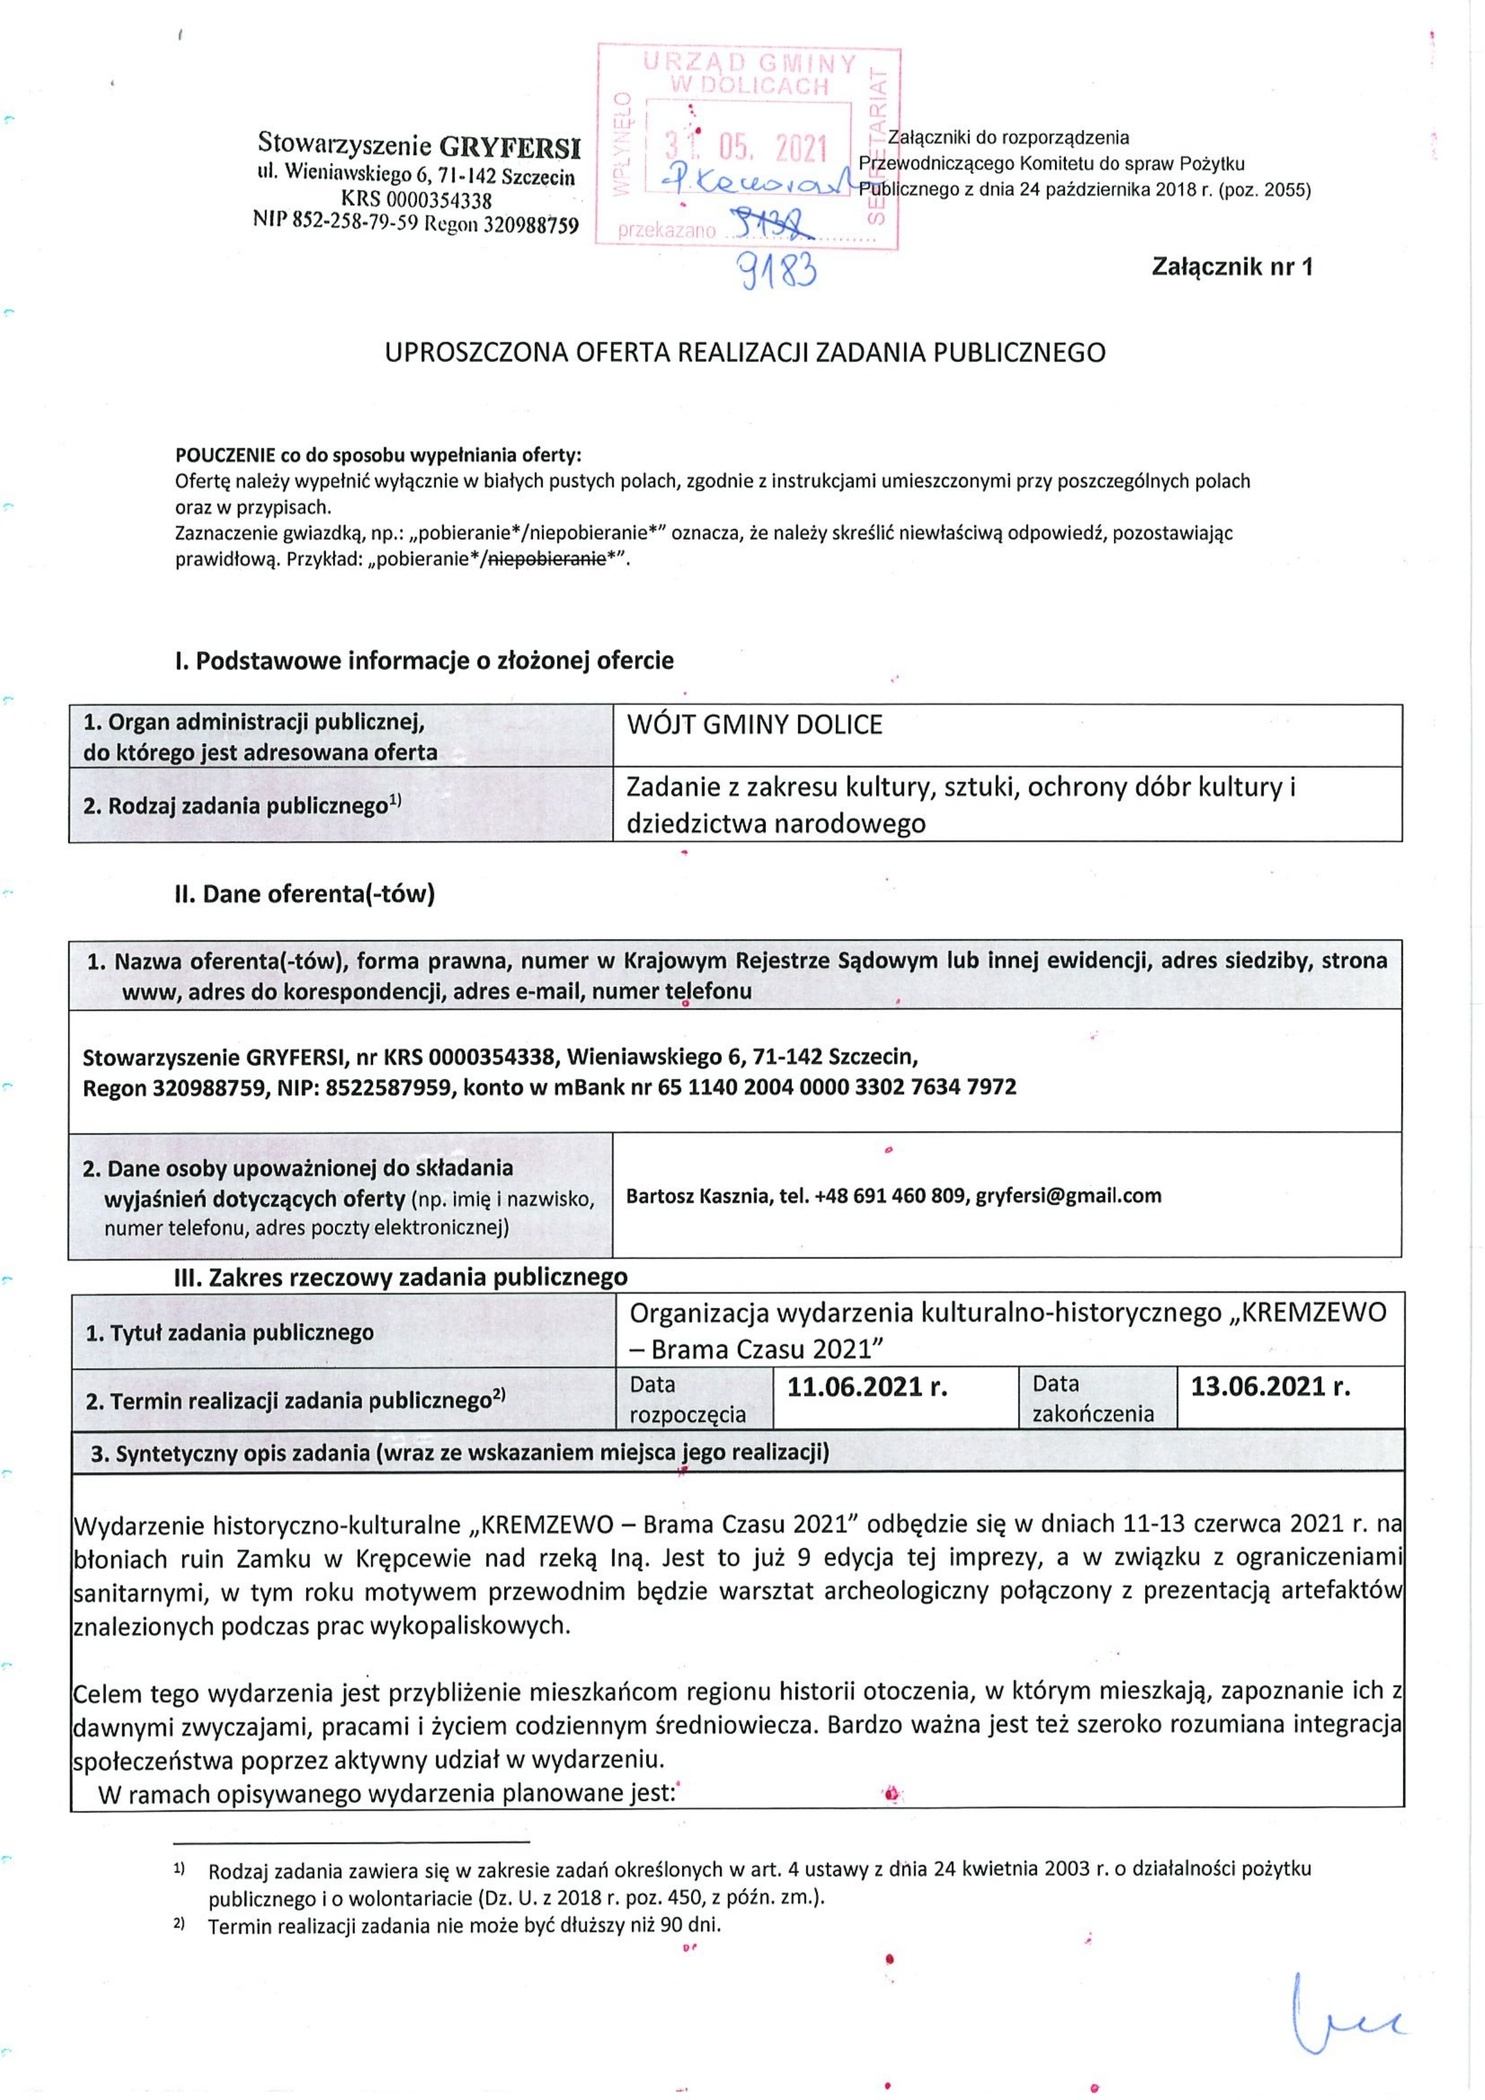

In [ ]:
sample = train[0]

display(sample["image"])

In [ ]:
sample["image"].save("sample_document.png")

# OCR part

In [ ]:
print(paddle.__version__)
print(paddle.device.get_device())

3.3.1
cpu


In [ ]:
ocr = PaddleOCR(lang="pl", enable_mkldnn=False)
result = ocr.predict("sample_document.png")

print(result)

Creating model: ('PP-LCNet_x1_0_doc_ori', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-LCNet_x1_0_doc_ori`.
Creating model: ('UVDoc', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/UVDoc`.
Creating model: ('PP-LCNet_x1_0_textline_ori', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-LCNet_x1_0_textline_ori`.
Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP

[{'input_path': 'sample_document.png', 'page_index': None, 'doc_preprocessor_res': {'input_path': None, 'page_index': None, 'input_img': array([[[255, ..., 255],
        ...,
        [255, ..., 255]],

       ...,

       [[255, ..., 255],
        ...,
        [255, ..., 255]]], dtype=uint8), 'model_settings': {'use_doc_orientation_classify': True, 'use_doc_unwarping': True}, 'angle': 0, 'rot_img': array([[[255, ..., 255],
        ...,
        [255, ..., 255]],

       ...,

       [[255, ..., 255],
        ...,
        [255, ..., 255]]], dtype=uint8), 'output_img': array([[[255, ..., 255],
        ...,
        [255, ..., 255]],

       ...,

       [[255, ..., 255],
        ...,
        [255, ..., 254]]], dtype=uint8)}, 'dt_polys': [array([[604,   0],
       ...,
       [605,  40]], dtype=int16), array([[861,   7],
       ...,
       [857, 133]], dtype=int16), array([[637,  37],
       ...,
       [638,  72]], dtype=int16), array([[573,  63],
       ...,
       [573, 202]], dtype=int1

In [ ]:
text = result[0]['rec_texts']

full_texts = " ".join(text)

In [ ]:
full_texts

'URZAD GMINY _A WDOLICACH PLYELO Stowarzyszenie GRYFERSI 31:05.2021 Załączniki do rozporządzenia ul. Wieniawskiego 6, 71-142 Szczecin Przewodniczącego Komitetu do spraw Pożytku PtPublicznego z dnia 24 pażdziernika 2018 r. (poz. 2055) KRS 0000354338 NIP 852-258-79-59 Regon 320988759 przekazano 913 S 9183 Załącznik nr 1 UPROSZCZONA OFERTA REALIZACJI ZADANIA PUBLICZNEGO POUCZENIE co do sposobu wypełniania oferty: Ofertę należy wypełnić wyłącznie w białych pustych polach, zgodnie z instrukcjami umieszczonymi przy poszczególnych polach oraz w przypisach. Zaznaczenie gwiazdką, np.: pobieranie*/niepobieranie*" oznacza, że należy skreślić niewłaściwą odpowiedź, pozostawiając prawidłowa. Przykład: pobieranie*/niepobieranie*". I. Podstawowe informacje o złożonej ofercie 1. Organ administracji publicznej, WÓJT GMINY DOLICE do którego jest adresowana oferta Zadanie z zakresu kultury, sztuki, ochrony dóbr kultury i 2. Rodzaj zadania publicznego1) dziedzictwa narodowego II. Dane oferenta(-tów) 1. Na

##information extraction

In [ ]:
def extract_data(text):

    data = {}

    # NIP
    nip = re.search(
        r"NIP[:\s]*([0-9]{3}[-\s]?[0-9]{3}[-\s]?[0-9]{2}[-\s]?[0-9]{2}|[0-9]{10})",
        text,
        re.IGNORECASE
    )

    # KRS
    krs = re.search(
        r"KRS[:\s]*([0-9]{10})",
        text,
        re.IGNORECASE
    )

    # REGON
    regon = re.search(
        r"REGON[:\s]*([0-9]{9}|[0-9]{14})",
        text,
        re.IGNORECASE
    )

    # Dates
    dates = re.findall(
        r"\d{2}\.\d{2}\.\d{4}",
        text
    )

    data["nip"] = nip.group(1) if nip else None
    data["krs"] = krs.group(1) if krs else None
    data["regon"] = regon.group(1) if regon else None
    data["dates"] = dates

    return data

In [ ]:
extracted = extract_data(full_texts)

In [ ]:
extracted

{'nip': '852-258-79-59',
 'krs': '0000354338',
 'regon': '320988759',
 'dates': ['11.06.2021', '13.06.2021']}

# LLM recognition and analysis

In [ ]:
api_key = getpass("Enter your DeepSeek API key: ")

client = OpenAI(
    api_key=api_key,
    base_url="https://api.deepseek.com"
)

print("DeepSeek client initialized!")

Enter your DeepSeek API key: ··········
DeepSeek client initialized!


In [ ]:
system_prompt = """
You are an expert document understanding system
specialized in Polish business and legal documents.

Your task is to analyze OCR-extracted text and identify
the structure and meaning of the document.

Follow these rules:

1. Identify the document type.
2. Identify all organizations and their roles.
3. Identify all persons and their relationships to organizations.
4. Extract available identifiers:
   NIP, REGON, KRS.
5. Extract important dates and explain their meaning.
6. Identify representatives and signatories if explicitly stated.
7. Do not confuse the applicant, recipient, client,
   contractor, representative or authority.
8. Never invent missing information.
9. If a role cannot be determined, use "unknown".
10. For every extracted field, provide an exact supporting
    quotation from the OCR text.
11. If OCR text is ambiguous or corrupted, mention it.

Return ONLY valid JSON.

Use this JSON structure:

{
  "document_type": {
    "value": "string",
    "evidence": "string"
  },
  "parties": [
    {
      "name": "string",
      "role": "string",
      "identifiers": {
        "nip": null,
        "regon": null,
        "krs": null
      },
      "evidence": "string"
    }
  ],
  "persons": [
    {
      "name": "string",
      "role": "string",
      "organization": null,
      "evidence": "string"
    }
  ],
  "dates": [
    {
      "value": "string",
      "purpose": "string",
      "evidence": "string"
    }
  ],
  "uncertainties": []
}
"""

In [ ]:
import json

user_prompt = f"""
Analyze the following Polish document.

Identify all parties, their roles, representatives,
identifiers and important dates.

Remember:
- Distinguish between document parties and representatives.
- Do not assume that the first organization is the client.
- If the role is unclear, return "unknown".
- Every extracted value must have supporting evidence.
- Return valid JSON only.

DOCUMENT TEXT:

{full_texts}
"""

response = client.chat.completions.create(
    model="deepseek-flash",
    messages=[
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt}
    ],
    response_format={"type": "json_object"},
    max_tokens=10000
)

raw_result = response.choices[0].message.content

data = json.loads(raw_result)

print(json.dumps(data, indent=2, ensure_ascii=False))

{
  "document_type": {
    "value": "Uproszczona oferta realizacji zadania publicznego",
    "evidence": "UPROSZCZONA OFERTA REALIZACJI ZADANIA PUBLICZNEGO"
  },
  "parties": [
    {
      "name": "Stowarzyszenie GRYFERSI",
      "role": "oferent (applicant) submitting the simplified offer",
      "identifiers": {
        "nip": "8522587959",
        "regon": "320988759",
        "krs": "0000354338"
      },
      "evidence": "II. Dane oferenta(-tów) 1. Nazwa oferenta(-tów), forma prawna, numer w Krajowym Rejestrze Sądowym lub innej ewidencji, adres siedziby, strona www, adres do korespondencji, adres e-mail, numer telefonu Stowarzyszenie GRYFERSI, nr KRS 0000354338, Wieniawskiego 6, 71-142 Szczecin, Regon 320988759, NIP: 8522587959"
    },
    {
      "name": "Wójt Gminy Dolice",
      "role": "organ administracji publicznej, adresat oferty (public administration authority / recipient)",
      "identifiers": {
        "nip": null,
        "regon": null,
        "krs": null
      },
  